# Redes: campañas, solapamiento y pérdida prevenible

## Resumen de la ejecución

Datos sintéticos; resultados de esta ejecución:

- **Beneficio ranking aditivo con K=2 (COP):** 110000.0
- **Beneficio cobertura conjunta K=2 (COP):** 220000.0
- **Presupuestos contrastados con oráculo:** 4

Los supuestos, límites y contraejemplos se explican junto a cada experimento.

## Objetivo y método

¿Por qué sumar beneficios individuales puede asignar dos revisiones a la misma pérdida? Derivamos cobertura máxima y contrastamos un MILP contra enumeración exacta.

### Supuestos y población

Tres acciones de investigación cubren conjuntos conocidos en un grafo hipotético. Se supone eficacia uno sobre exposición cubierta y un mismo costo por acción. No se estima que investigar realmente contenga una campaña.

Todos los datos son sintéticos. Las cifras ilustran mecanismos y no constituyen desempeño observado en una entidad. Fecha de desarrollo: 21 de octubre de 2026.

## Entorno reproducible

Ejecutar en orden, desde esta carpeta o una subcarpeta de la línea de fraude. La semilla y los parámetros quedan en las celdas; no se consulta internet ni se leen datos de clientes.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score, brier_score_loss
base = next(p for p in [Path.cwd(), *Path.cwd().parents] if p.name == 'fraud-and-anomaly-research')
sys.path.insert(0, str(base / 'loss-minimization-engine'))
from src.engine import Case, Action, Scenario, optimize, expected_cost, shared_entity_count
rng = np.random.default_rng(20261021)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False, 'grid.alpha': .25})
BLUE, TEAL, GOLD, PURPLE = '#386A96', '#217A72', '#B37D2E', '#73579D'
pd.options.display.float_format = '{:,.4f}'.format

No event loop hook running.


## 1. Beneficio por unión, no por suma de listas


Con acción $i$ que cubre $S_i$, el beneficio correcto bajo cobertura perfecta es
$$B(A)=\sum_{j\in\cup_{i\in A}S_i}\ell_j-\sum_{i\in A}c_i.$$

Sumar $\sum_{i\in A}\sum_{j\in S_i}\ell_j$ cuenta pérdidas varias veces si los conjuntos se solapan. Aquí $\ell_j$ es pérdida prevenible esperada, no saldo bruto.

,acciones,beneficio_union_COP
0,A+B,"110,000.0000"
1,A+C,"220,000.0000"
2,B+C,"220,000.0000"


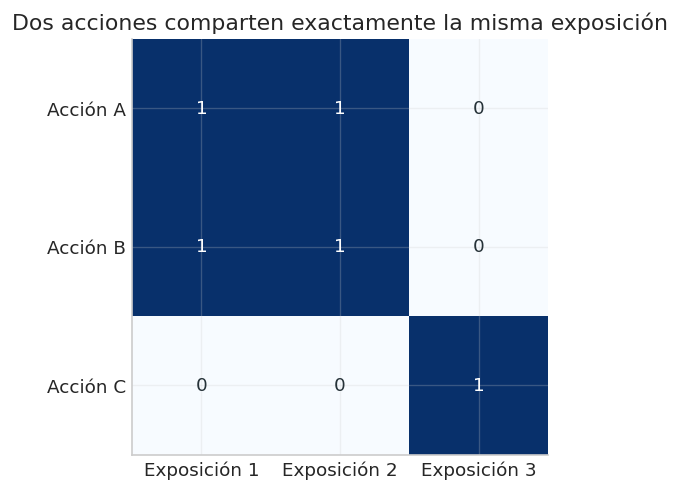

In [2]:
import itertools
from scipy.optimize import milp,Bounds,LinearConstraint
exposure=np.array([60_000.,60_000.,110_000.])
coverage=np.array([[1,1,0],[1,1,0],[0,0,1]])
cost=np.array([5_000.,5_000.,5_000.])
def benefit(indices):
    if not len(indices):return 0.
    covered=coverage[list(indices)].any(axis=0)
    return float(exposure[covered].sum()-cost[list(indices)].sum())
naive_order=np.argsort(-(coverage@exposure-cost),kind='stable')
naive_two=naive_order[:2].tolist()
all_pairs=list(itertools.combinations(range(3),2))
exact_two=max(all_pairs,key=benefit)
display(pd.DataFrame({'acciones':['A+B','A+C','B+C'],'beneficio_union_COP':[benefit(a) for a in all_pairs]}))
fig,ax=plt.subplots();ax.imshow(coverage,cmap='Blues',vmin=0,vmax=1)
ax.set_xticks(range(3),['Exposición 1','Exposición 2','Exposición 3']);ax.set_yticks(range(3),['Acción A','Acción B','Acción C'])
for i in range(3):
    for j in range(3):ax.text(j,i,str(coverage[i,j]),ha='center',va='center',color='white' if coverage[i,j] else '#263238')
ax.set_title('Dos acciones comparten exactamente la misma exposición');plt.show()

A y B parecen igualmente atractivas si se suman listas. Sin embargo, revisarlas juntas no alcanza la exposición 3. El ejemplo es una restricción de conjunto conocida, no un resultado empírico de grafos.

## 2. MILP con variables de cobertura


Con $x_i$ acción y $z_j$ exposición cubierta:
$$\max\sum_j\ell_jz_j-\sum_i c_ix_i,\quad z_j\le\sum_{i:j\in S_i}x_i,\quad\sum_i x_i\le K.$$

$x,z$ son binarias. Al tener pérdidas no negativas, el objetivo hace que se marque la cobertura disponible. Esta formulación no representa eficacia parcial ni efectos negativos entre acciones.

,K,beneficio_MILP_COP,oracle_COP,suma_ingenua_realizada_COP
0,0,0.0000,0.0000,0.0000
1,1,"115,000.0000","115,000.0000","115,000.0000"
2,2,"220,000.0000","220,000.0000","110,000.0000"
3,3,"220,000.0000","220,000.0000","215,000.0000"


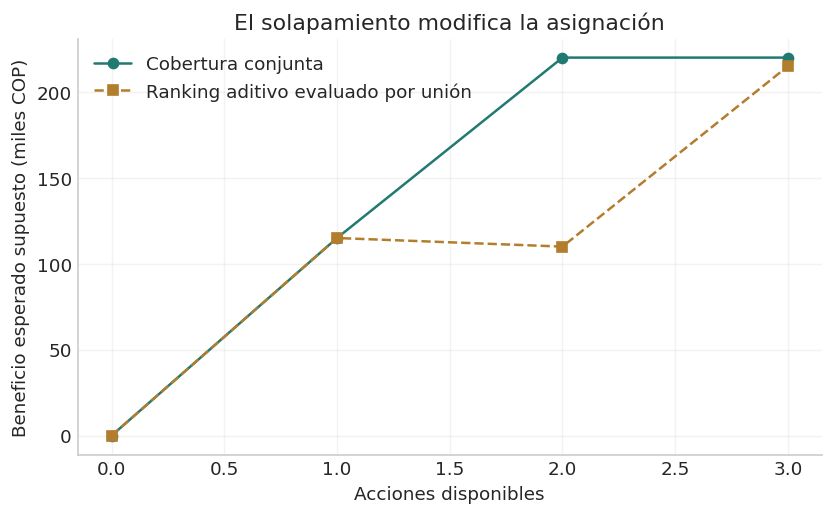

In [3]:
def coverage_milp(K):
    # Variables [x_A,x_B,x_C,z_1,z_2,z_3]. Negative benefit for minimization.
    objective=np.r_[cost,-exposure]/1000
    rows=[np.r_[np.ones(3),np.zeros(3)]]
    for j in range(3):
        row=np.zeros(6);row[:3]=-coverage[:,j];row[3+j]=1;rows.append(row)
    result=milp(objective,integrality=np.ones(6),bounds=Bounds(np.zeros(6),np.ones(6)),
                constraints=LinearConstraint(np.array(rows),[-np.inf]*4,[K,0,0,0]),options={'mip_rel_gap':0})
    assert result.status==0
    selected=np.flatnonzero(result.x[:3]>.5).tolist()
    return selected,benefit(selected)
frontier=[]
for K in range(4):
    chosen,value=coverage_milp(K)
    oracle=max(benefit(s) for k in range(K+1) for s in itertools.combinations(range(3),k))
    frontier.append({'K':K,'beneficio_MILP_COP':value,'oracle_COP':oracle,'suma_ingenua_realizada_COP':benefit(naive_order[:K].tolist())})
frontier=pd.DataFrame(frontier);display(frontier)
fig,ax=plt.subplots();ax.plot(frontier['K'],frontier['beneficio_MILP_COP']/1000,marker='o',color=TEAL,label='Cobertura conjunta')
ax.plot(frontier['K'],frontier['suma_ingenua_realizada_COP']/1000,marker='s',linestyle='--',color=GOLD,label='Ranking aditivo evaluado por unión')
ax.set(xlabel='Acciones disponibles',ylabel='Beneficio esperado supuesto (miles COP)',title='El solapamiento modifica la asignación');ax.legend();plt.show()

La búsqueda exhaustiva da un oráculo independiente en este problema pequeño. La tercera acción no añade exposición cuando las otras ya cubren todo y puede reducir beneficio por su costo. La optimización permite usar menos de K.

## 3. Eficacia parcial: un supuesto adicional


Si dos intervenciones tienen eficacia $q$ sobre la misma exposición y sus éxitos fueran independientes, la probabilidad conjunta sería $1-(1-q)^2$, no $2q$. La independencia es un supuesto fuerte: si ambas dependen de la misma verificación podrían no aportar nada adicional.

In [4]:
q=np.array([.2,.5,.8])
display(pd.DataFrame({'q':q,'suma_incorrecta':2*q,'independencia_supuesta':1-(1-q)**2,'dependencia_total':q}))

,q,suma_incorrecta,independencia_supuesta,dependencia_total
0,0.2000,0.4000,0.3600,0.2000
1,0.5000,1.0000,0.7500,0.5000
2,0.8000,1.6000,0.9600,0.8000


El MILP de arriba usa cobertura perfecta y no implementa esta extensión parcial. No transferir la aparente ganancia de una fórmula de independencia a una campaña real sin conocer cómo actúa la intervención.

## Comprobaciones y límites

Las identidades y contraejemplos siguientes son parte del experimento; no verifican desempeño productivo.

In [5]:
assert benefit(exact_two)>benefit(naive_two)
assert np.allclose(frontier['beneficio_MILP_COP'],frontier['oracle_COP'])
assert np.all(1-(1-q)**2<=1)

## Resultados computados

In [6]:
metrics = {'Beneficio ranking aditivo con K=2 (COP)': benefit(naive_two), 'Beneficio cobertura conjunta K=2 (COP)': benefit(exact_two), 'Presupuestos contrastados con oráculo': len(frontier)}
print("LAB_METRICS:" + json.dumps(metrics, ensure_ascii=False))

LAB_METRICS:{"Beneficio ranking aditivo con K=2 (COP)": 110000.0, "Beneficio cobertura conjunta K=2 (COP)": 220000.0, "Presupuestos contrastados con oráculo": 4}


## Ideas y preguntas para continuar

1. Modelar cobertura incierta y medir sensibilidad a vínculos falsos.
2. Estimar el efecto incremental de investigar un segundo caso de una campaña.
3. Añadir tiempos heterogéneos y retraso hasta contener fondos.
4. Contrastar cobertura máxima, submodularidad y complementariedad antes de elegir un optimizador.

## Fuentes y relación con el proyecto

- [SciPy: programación lineal entera](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html).
- El contraejemplo de unión se deriva y enumera aquí, sin usar etiquetas de clientes.

Consultar también `../README.md` y `../../MODEL_AND_LOSS_METHODS.md`.